# Required Assignment 17.1 — Comparing Classifiers

**UC Berkeley Professional Certificate in Machine Learning & Artificial Intelligence**  
**Business case:** Portuguese bank term-deposit telemarketing  
**Required classifiers:** Logistic regression, k-nearest neighbors (KNN), decision tree, support vector machine (SVM).

This executed notebook follows the supplied `prompt_III.ipynb` questions 1–11 and adds a reproducible, leakage-conscious CRISP-DM analysis. It uses actual UCI bank data. The random modeling subset is disclosed; no synthetic outcomes are used.

**Decision to support:** Which customers should a bank *prioritize for a future outbound call* under limited calling capacity? Results are associations with historical subscription, not proofs of causation or measured campaign profitability.

**Data citation:** Moro, S., Cortez, P. & Rita, P. (2014). A Data-Driven Approach to Predict the Success of Bank Telemarketing. *Decision Support Systems* **62**, 22–31. [DOI](https://doi.org/10.1016/j.dss.2014.03.001).

## 1. Business understanding — starter problems 1 and 4

**Answer to Problem 1:** The article accompanying the starter data reports **17 direct-marketing campaigns** carried out between **May 2008 and November 2010**. The rows are telephone contact records, **not 41,188 distinct customers**.

**Business objective (Problem 4):** Estimate the probability that an eligible customer will subscribe to a term deposit so that marketing staff can prioritize calls and evaluate whether prioritization beats untargeted calling. A bank should eventually consider contact cost, realized product revenue, campaign scheduling, and customer preferences/consent.

**Modeling safeguards:** An 88.7% majority class makes plain accuracy insufficient. We optimize **average precision (AP)** by stratified cross-validation because the bank wants to rank relatively rare positive outcomes and allocate finite call capacity; we also report ROC AUC, recall, precision, F1, balanced accuracy and accuracy. `duration` (call length) is unknown before a prospective call, so it is excluded from *all* deployable models. Imputation, scaling and one-hot encoding live inside cross-validated pipelines. Predictions describe historical marketing responses, not a tested intervention.

In [1]:
from pathlib import Path
import os, zipfile, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
SEED = 42
MODEL_N = 12000  # stratified sample for computationally affordable KNN/SVM/grid searches
FIG = Path('figures'); RESULT = Path('results')
FIG.mkdir(exist_ok=True); RESULT.mkdir(exist_ok=True)
print('Modeling sample:', MODEL_N, '| fixed random state:', SEED)

Modeling sample: 12000 | fixed random state: 42


## 2. Data understanding — starter problems 2 and 3

Source data are semicolon-separated. The loader accepts the provided source ZIP, raw CSV in the documented folder, or an explicit path. The full dataset is used for the **descriptive statistics**; model comparisons use a **12,000-row stratified subset** for reproducible runtime. The 10% course sample (`bank-additional.csv`) is *not* used as the primary data.

In [2]:
def load_source():
    env = os.environ.get('UC_BANK_DATA_PATH')
    paths = ([Path(env)] if env else []) + [
        Path('data/bank-additional-full.csv'),
        Path('data/bank-additional/bank-additional-full.csv'),
        Path('data/module17_starter.zip'),
        Path('module17_starter.zip'),
    ]
    for p in paths:
        if not p.is_file():
            continue
        if p.suffix.lower() == '.csv':
            return pd.read_csv(p, sep=';'), p.read_bytes(), str(p)
        if p.suffix.lower() == '.zip':
            with zipfile.ZipFile(p) as z:
                hits = [n for n in z.namelist() if n.endswith('bank-additional-full.csv')]
                if hits:
                    b=z.read(hits[0])
                    from io import BytesIO
                    return pd.read_csv(BytesIO(b),sep=';'), b, f'{p}!{hits[0]}'
    raise FileNotFoundError('Download official module17_starter.zip and place the full CSV in data/, or set UC_BANK_DATA_PATH.')

df, source_bytes, source_name = load_source()
source_hash = hashlib.sha256(source_bytes).hexdigest()
print('Source:', source_name, '| SHA256:', source_hash)
print('Shape:', df.shape, '| duplicated entire rows:', int(df.duplicated().sum()))
display(df.head(3))
assert df.shape == (41188, 21), 'Unexpected full-dataset version'
assert set(df.y.unique()) == {'yes','no'}

Source: data/bank-additional-full.csv | SHA256: 233e260d5d1d506a2c10381da5b8c2f75f2c08d1b373ca7b825e39ebe1bd30df
Shape: (41188, 21) | duplicated entire rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
positive_rate = (df.y == 'yes').mean()
unknown_counts = (df == 'unknown').sum().sort_values(ascending=False)
print('Target distribution (full source):')
display(df.y.value_counts().rename_axis('subscribed').to_frame('rows').assign(percent=lambda t: (100*t.rows/len(df)).round(2)))
print('Unknown-coded values by field (top six):')
display(unknown_counts[unknown_counts>0].head(6).rename('unknown rows').to_frame())
print('Continuous variable summary:')
display(df[['age','campaign','duration','previous','euribor3m']].describe().round(2))
print('pdays == 999 sentinel:', int((df.pdays==999).sum()))

Target distribution (full source):


,rows,percent
subscribed,,
no,36548,88.73
yes,4640,11.27


Unknown-coded values by field (top six):


,unknown rows
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


Continuous variable summary:


,age,campaign,duration,previous,euribor3m
count,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,2.57,258.29,0.17,3.62
std,10.42,2.77,259.28,0.49,1.73
min,17.00,1.00,0.00,0.00,0.63
25%,32.00,1.00,102.00,0.00,1.34
50%,38.00,2.00,180.00,0.00,4.86
75%,47.00,3.00,319.00,0.00,4.96
max,98.00,56.00,4918.00,7.00,5.04


pdays == 999 sentinel: 39673


**Missingness and types (Problem 3):** No ordinary NaNs appear in the original CSV, but `unknown` marks missing/uncertain categories (especially `default`), and `pdays=999` denotes no previous contact—not 999 elapsed days. We preserve `unknown` as an explicit category, create a separate `previously_contacted` indicator, and set the sentinel to missing for numeric imputation. These transformations are not outcomes leakage. Several numeric macro variables are date-associated; the limitations section discusses temporal stability.

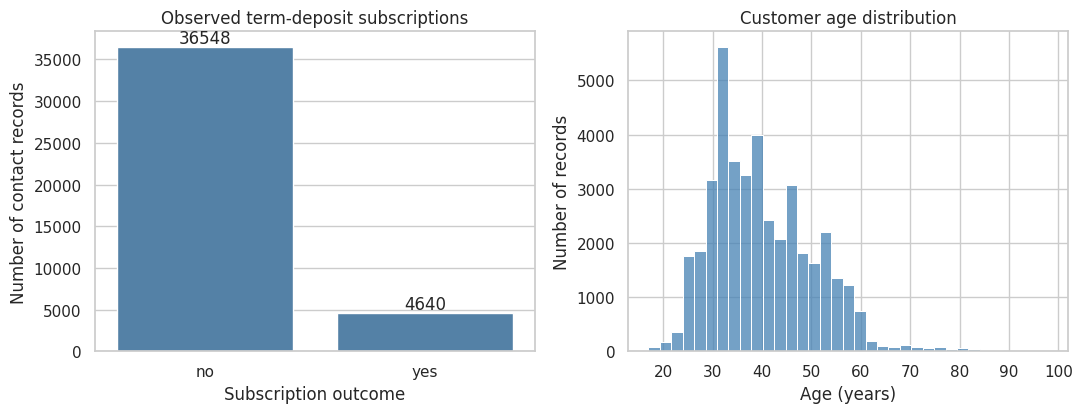

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
sns.countplot(data=df,x='y',order=['no','yes'],ax=axes[0],color='steelblue');axes[0].set(title='Observed term-deposit subscriptions',xlabel='Subscription outcome',ylabel='Number of contact records')
for c in axes[0].containers:axes[0].bar_label(c,fmt='%d')
sns.histplot(df['age'],bins=35,ax=axes[1],color='steelblue');axes[1].set(title='Customer age distribution',xlabel='Age (years)',ylabel='Number of records')
fig.tight_layout();fig.savefig(FIG/'01_class_balance_age.png',dpi=155,bbox_inches='tight');plt.show()

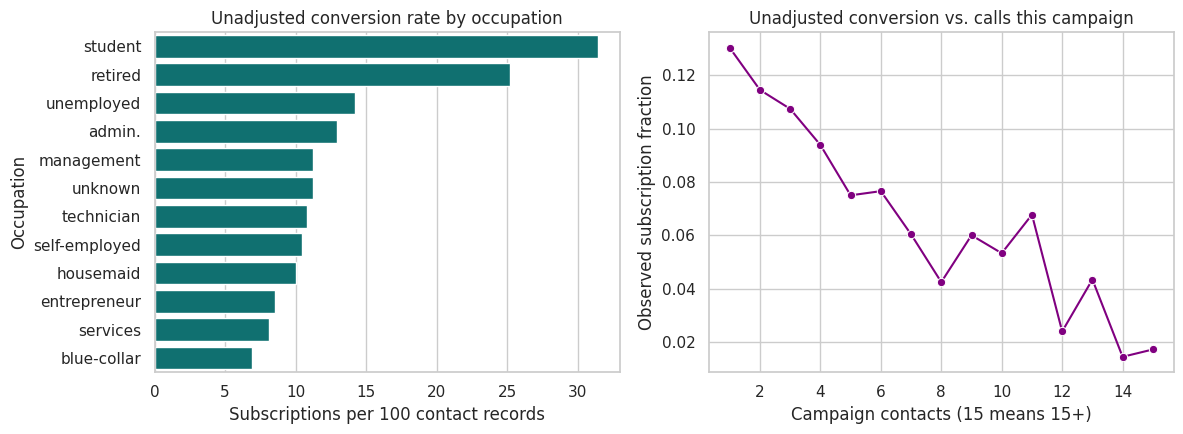

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
cat=(df.groupby('job').y.apply(lambda v:(v=='yes').mean()).sort_values(ascending=False)*100)
sns.barplot(x=cat.values,y=cat.index,ax=axes[0],color='teal');axes[0].set(title='Unadjusted conversion rate by occupation',xlabel='Subscriptions per 100 contact records',ylabel='Occupation')
df_plot=df.assign(odometer_call_count=df.campaign.clip(upper=15),success=(df.y=='yes').astype(int))
sns.lineplot(data=df_plot.groupby('odometer_call_count',as_index=False).success.mean(),x='odometer_call_count',y='success',marker='o',ax=axes[1],color='purple')
axes[1].set(title='Unadjusted conversion vs. calls this campaign',xlabel='Campaign contacts (15 means 15+)',ylabel='Observed subscription fraction')
fig.tight_layout();fig.savefig(FIG/'02_descriptive_segments.png',dpi=155,bbox_inches='tight');plt.show()

## 3. Data preparation — starter problems 5 and 6

The starter asks initially for bank-client variables. We first inspect those **seven client descriptors** (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`). For the practical *pre-call* model comparison we additionally use available previous-contact, planned-call and macroeconomic information, but **never `duration`**. Every model receives exactly the same predictors and stratified train/test split. The train/test split precedes fitting preprocessing, avoiding test-set contamination.

**Interpretive caution:** `month` and `day_of_week` represent contact date in historical records. For live deployment these should be available as planned scheduling variables, not as outcomes; if scheduling is unknown they should be omitted. Economic indicators have potential era dependence.

In [6]:
base_client_cols=['age','job','marital','education','default','housing','loan']
assert set(base_client_cols).issubset(df.columns)
def feature_frame(raw):
    X=raw.drop(columns=['y','duration']).copy()
    X['previously_contacted']=(X['pdays']!=999).astype(int)
    X['pdays']=X['pdays'].replace(999,np.nan)
    return X

X_all=feature_frame(df)
y_all=(df['y']=='yes').astype(int)
assert 'duration' not in X_all and 'y' not in X_all
# The fixed stratified modeling sample preserves the observed minority fraction.
subset_index,_=train_test_split(np.arange(len(df)),train_size=MODEL_N,random_state=SEED,stratify=y_all)
X=X_all.iloc[subset_index].copy(); y=y_all.iloc[subset_index].copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
num_cols=X_train.select_dtypes(include='number').columns.tolist()
cat_cols=X_train.select_dtypes(exclude='number').columns.tolist()
preprocess=ColumnTransformer(transformers=[
    ('numeric', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
    ('categorical', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
])
print('Available client-only fields:',', '.join(base_client_cols))
print('Pre-call predictors:', len(X.columns), '(numeric',len(num_cols),'categorical',len(cat_cols),')')
print('Train / holdout:',len(X_train),'/',len(X_test),'| positive shares:',round(y_train.mean(),4),round(y_test.mean(),4))
print('Duration excluded:', 'duration' not in X.columns)

Available client-only fields: age, job, marital, education, default, housing, loan
Pre-call predictors: 20 (numeric 10 categorical 10 )
Train / holdout: 9600 / 2400 | positive shares: 0.1127 0.1125
Duration excluded: True


In [7]:
# Starter Problem 5/8: fit the simple initial model using ONLY the seven client attributes.
client_preprocess = ColumnTransformer(transformers=[
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), ['age']),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                             ('encode', OneHotEncoder(handle_unknown='ignore'))]), base_client_cols[1:])
])
client_only_lr = Pipeline([('prep', client_preprocess),
                           ('classifier', LogisticRegression(solver='liblinear',max_iter=2000,random_state=SEED))])
client_only_lr.fit(X_train[base_client_cols],y_train)
client_scores = scores(client_only_lr,X_test[base_client_cols],y_test) if 'scores' in globals() else None
# The scoring helper is defined below; compute one interpretable metric here directly.
client_only_ap = average_precision_score(y_test,client_only_lr.predict_proba(X_test[base_client_cols])[:,1])
print('Client-only logistic regression (seven client fields): holdout AP',round(client_only_ap,3))
print('Below we compare expanded pre-call features, for all four classifiers, on identical records.')

Client-only logistic regression (seven client fields): holdout AP 0.199
Below we compare expanded pre-call features, for all four classifiers, on identical records.


## 4. Baseline and default models — starter problems 7–10

A majority-class baseline predicts `no` for everyone. It will achieve deceptively high accuracy but **zero recall** on subscribers. A stratified prevalence baseline for average precision is approximately the positive fraction. Default logistic regression, KNN, decision tree and SVM are compared on the same holdout, along with training times. **No tuning uses holdout data.**

In [8]:
def scores(est, xx, yy):
    pred=est.predict(xx)
    if hasattr(est,'predict_proba'): score=est.predict_proba(xx)[:,1]
    elif hasattr(est,'decision_function'): score=est.decision_function(xx)
    else:score=pred
    return dict(accuracy=accuracy_score(yy,pred),balanced_accuracy=balanced_accuracy_score(yy,pred),
        precision=precision_score(yy,pred,zero_division=0),recall=recall_score(yy,pred,zero_division=0),
        f1=f1_score(yy,pred,zero_division=0),average_precision=average_precision_score(yy,score),
        roc_auc=roc_auc_score(yy,score))

models={
 'Logistic regression':LogisticRegression(solver='liblinear',max_iter=2000,random_state=SEED),
 'KNN':KNeighborsClassifier(n_neighbors=5),
 'Decision tree':DecisionTreeClassifier(random_state=SEED),
 'SVM (RBF)':SVC(kernel='rbf',random_state=SEED),
}
default_fitted={};rows=[]
baseline=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
rows.append(dict(model='Majority baseline',train_seconds=0,train_accuracy=accuracy_score(y_train,baseline.predict(X_train)),test_accuracy=accuracy_score(y_test,baseline.predict(X_test)),**{k:v for k,v in scores(baseline,X_test,y_test).items() if k!='accuracy'}))
for name,clf in models.items():
    est=Pipeline([('prep',preprocess),('classifier',clf)])
    t0=time.perf_counter();est.fit(X_train,y_train);elapsed=time.perf_counter()-t0
    met=scores(est,X_test,y_test)
    rows.append(dict(model=name,train_seconds=elapsed,train_accuracy=accuracy_score(y_train,est.predict(X_train)),test_accuracy=met.pop('accuracy'),**met))
    default_fitted[name]=est
default_table=pd.DataFrame(rows).set_index('model')
default_table.to_csv(RESULT/'default_model_comparison.csv')
display(default_table.round(3))
print('Majority-class accuracy:',round(1-y_test.mean(),3),'| all-negative baseline recall is exactly 0')

,train_seconds,train_accuracy,test_accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc
model,,,,,,,,,
Majority baseline,0.000,0.887,0.888,0.500,0.000,0.000,0.000,0.112,0.500
Logistic regression,0.100,0.901,0.903,0.622,0.680,0.259,0.375,0.462,0.775
KNN,0.039,0.912,0.892,0.627,0.535,0.285,0.372,0.321,0.726
Decision tree,0.098,0.998,0.850,0.627,0.335,0.341,0.338,0.188,0.627
SVM (RBF),2.364,0.908,0.902,0.607,0.693,0.226,0.341,0.402,0.692


Majority-class accuracy: 0.888 | all-negative baseline recall is exactly 0


## 5. Cross-validation and hyperparameter search — starter problem 11

To avoid choosing hyperparameters based on the test set, we use **3-fold stratified cross-validation on training records only** and select each classifier's highest-average-precision configuration. Grids intentionally remain small enough for an ordinary student laptop; they are *not* claims of exhaustive optimization. The same preprocessing is refitted inside each CV fold. SVM ranking uses `decision_function` (no costly probability calibration).

In [9]:
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
grids={
 'Logistic regression':{'classifier__C':[0.2,1.0,5.0], 'classifier__class_weight':[None,'balanced']},
 'KNN':{'classifier__n_neighbors':[11,31,51], 'classifier__weights':['uniform','distance']},
 'Decision tree':{'classifier__max_depth':[4,8,12], 'classifier__min_samples_leaf':[20,80], 'classifier__class_weight':['balanced']},
 'SVM (RBF)':{'classifier__C':[0.5,2], 'classifier__class_weight':[None,'balanced']},
}
searches={};search_summary=[];tuned_rows=[]
for name,clf in models.items():
    model=Pipeline([('prep',preprocess),('classifier',clf)])
    gs=GridSearchCV(model,grids[name],scoring='average_precision',cv=cv,n_jobs=2,refit=True,return_train_score=False)
    t0=time.perf_counter();gs.fit(X_train,y_train);elapsed=time.perf_counter()-t0
    searches[name]=gs
    search_summary.append({'model':name,'cv_AP':gs.best_score_,'best_parameters':str(gs.best_params_),'search_seconds':elapsed,'grid_candidates':len(gs.cv_results_['params'])})
    m=scores(gs.best_estimator_,X_test,y_test)
    tuned_rows.append({'model':name,**m})
    print(name,'CV AP:',round(gs.best_score_,3),'holdout AP:',round(m['average_precision'],3),'time:',round(elapsed,1),'s')
search_table=pd.DataFrame(search_summary).sort_values('cv_AP',ascending=False)
tuned_table=pd.DataFrame(tuned_rows).set_index('model')
search_table.to_csv(RESULT/'cross_validation_grid_search.csv',index=False)
tuned_table.to_csv(RESULT/'tuned_model_holdout_metrics.csv')
display(search_table.round(3));display(tuned_table.round(3))

Logistic regression CV AP: 0.448 holdout AP: 0.462 time: 3.4 s


KNN CV AP: 0.416 holdout AP: 0.427 time: 2.3 s


Decision tree CV AP: 0.41 holdout AP: 0.461 time: 0.8 s


SVM (RBF) CV AP: 0.407 holdout AP: 0.4 time: 16.3 s


,model,cv_AP,best_parameters,search_seconds,grid_candidates
0,Logistic regression,0.448,"{'classifier__C': 1.0, 'classifier__class_weig...",3.426,6
1,KNN,0.416,"{'classifier__n_neighbors': 51, 'classifier__w...",2.267,6
2,Decision tree,0.410,"{'classifier__class_weight': 'balanced', 'clas...",0.838,6
3,SVM (RBF),0.407,"{'classifier__C': 0.5, 'classifier__class_weig...",16.311,4


,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc
model,,,,,,,
Logistic regression,0.903,0.622,0.680,0.259,0.375,0.462,0.775
KNN,0.903,0.619,0.694,0.252,0.370,0.427,0.755
Decision tree,0.787,0.728,0.296,0.652,0.407,0.461,0.785
SVM (RBF),0.900,0.601,0.674,0.215,0.326,0.400,0.689


## 6. Evaluation — untouched holdout, model selection and errors

**Primary score:** average precision (AP) on the test holdout, interpreted relative to the roughly 11% base prevalence. **Operational ranking check:** captured subscribers within the top 20% of contacts ranked by the model, with corresponding precision/lift. These are retrospective estimates, not evidence that different contacts would causally respond to a new campaign. Other thresholds and calling costs require separate validation.

The highest CV-AP model is selected without looking at holdout scores.

In [10]:
winner_name=search_table.iloc[0]['model']
winner=searches[winner_name].best_estimator_
if hasattr(winner,'predict_proba'): win_score=winner.predict_proba(X_test)[:,1]
else: win_score=winner.decision_function(X_test)
cut=np.argsort(-win_score)[:int(round(.20*len(win_score)))]
subset_precision=float(y_test.iloc[cut].mean())
subset_recall=float(y_test.iloc[cut].sum()/y_test.sum())
lift=subset_precision/float(y_test.mean())
ranking={'cv_selected_model':winner_name,'n_holdout':len(y_test),'prevalence':float(y_test.mean()),'top_20pct_precision':subset_precision,'top_20pct_recall':subset_recall,'top_20pct_lift':lift}
pd.Series(ranking).to_csv(RESULT/'ranking_at_20_percent.csv',header=['value'])
print('CV-selected model:',winner_name)
print('Contact top 20% of holdout:',round(subset_precision*100,1),'% subscription share; capture',round(subset_recall*100,1),'% of observed subscribers; lift',round(lift,2),'x')
print('Holdout confusion matrix: rows true 0/1, columns predicted 0/1')
display(pd.DataFrame(confusion_matrix(y_test,winner.predict(X_test)),index=['True no','True yes'],columns=['Pred no','Pred yes']))

CV-selected model: Logistic regression
Contact top 20% of holdout: 35.4 % subscription share; capture 63.0 % of observed subscribers; lift 3.15 x
Holdout confusion matrix: rows true 0/1, columns predicted 0/1


,Pred no,Pred yes
True no,2097,33
True yes,200,70


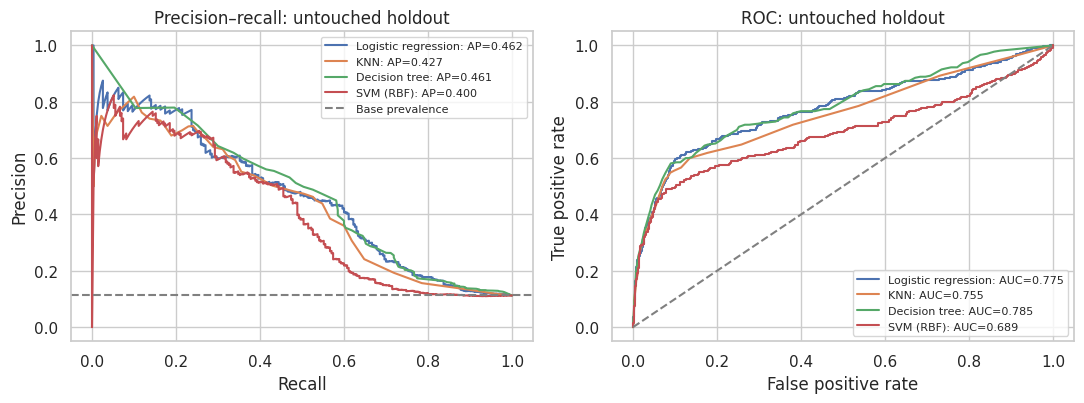

In [11]:
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
for name,gs in searches.items():
    est=gs.best_estimator_;sc=est.predict_proba(X_test)[:,1] if hasattr(est,'predict_proba') else est.decision_function(X_test)
    p,r,_=precision_recall_curve(y_test,sc)
    axs[0].plot(r,p,label=f'{name}: AP={average_precision_score(y_test,sc):.3f}')
    fpr,tpr,_=roc_curve(y_test,sc);axs[1].plot(fpr,tpr,label=f'{name}: AUC={roc_auc_score(y_test,sc):.3f}')
axs[0].axhline(y_test.mean(),ls='--',c='gray',label='Base prevalence');axs[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall: untouched holdout');axs[0].legend(fontsize=8)
axs[1].plot([0,1],[0,1],ls='--',c='gray');axs[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC: untouched holdout');axs[1].legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG/'03_pr_roc_comparison.png',dpi=160,bbox_inches='tight');plt.show()

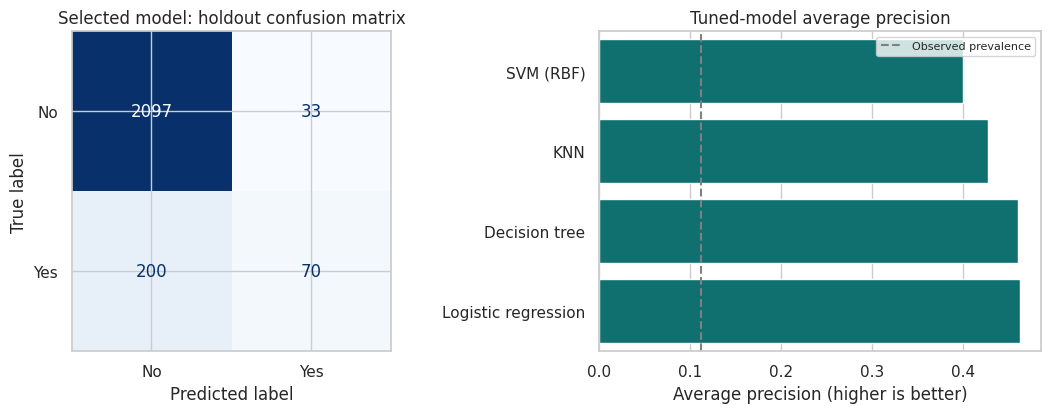

In [12]:
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
ConfusionMatrixDisplay.from_estimator(winner,X_test,y_test,ax=axs[0],display_labels=['No','Yes'],cmap='Blues',colorbar=False)
axs[0].set_title('Selected model: holdout confusion matrix')
res=tuned_table.sort_values('average_precision',ascending=True).reset_index()
sns.barplot(data=res,y='model',x='average_precision',ax=axs[1],color='teal')
axs[1].axvline(y_test.mean(),ls='--',c='gray',label='Observed prevalence');axs[1].legend(fontsize=8)
axs[1].set(title='Tuned-model average precision',xlabel='Average precision (higher is better)',ylabel='')
fig.tight_layout();fig.savefig(FIG/'04_confusion_model_comparison.png',dpi=160,bbox_inches='tight');plt.show()

## 7. Interpreting model coefficients and sensitivity

Logistic regression provides interpretable **associations** via coefficient signs and conditional log odds, not treatment effects. Coefficients are computed after **train-only** standardization/encoding and reported for the tuned logistic model regardless of which family won CV. Numeric continuous features are scaled, so an odds ratio refers to one *training-set standard deviation*, while one-hot terms refer to indicator shifts relative to the omitted/reference combination of correlated indicators. Correlated one-hot terms and predictors complicate interpretation. **Do not read a coefficient as a causal lift.**

In addition, feature permutation on the selected model measures **sensitivity of holdout AP** to shuffling a column; it does not establish causation or customer motivation.

In [13]:
lr=searches['Logistic regression'].best_estimator_
prep=lr.named_steps['prep']
feature_names=prep.get_feature_names_out()
coeff=lr.named_steps['classifier'].coef_.ravel()
coefs=pd.DataFrame({'encoded_feature':feature_names,'log_odds_coefficient':coeff,'conditional_odds_ratio':np.exp(np.clip(coeff,-20,20))})
coefs['absolute_coefficient']=coefs.log_odds_coefficient.abs()
coefs=coefs.sort_values('absolute_coefficient',ascending=False)
coefs.drop(columns='absolute_coefficient').to_csv(RESULT/'logistic_coefficients.csv',index=False)
print('Largest absolute logistic coefficients (one-hot and scaled features; descriptive associations):')
display(coefs[['encoded_feature','log_odds_coefficient','conditional_odds_ratio']].head(12).round(3))

Largest absolute logistic coefficients (one-hot and scaled features; descriptive associations):


,encoded_feature,log_odds_coefficient,conditional_odds_ratio
4,numeric__emp.var.rate,-1.388,0.250
50,categorical__month_mar,1.055,2.872
25,categorical__marital_unknown,0.845,2.329
51,categorical__month_may,-0.709,0.492
60,categorical__poutcome_failure,-0.665,0.514
52,categorical__month_nov,-0.661,0.516
7,numeric__euribor3m,0.579,1.785
44,categorical__contact_telephone,-0.561,0.570
5,numeric__cons.price.idx,0.548,1.729
22,categorical__marital_divorced,-0.533,0.587


,feature,AP_decrease_mean,AP_decrease_sd
14,emp.var.rate,0.3080,0.0042
15,cons.price.idx,0.0794,0.0056
19,previously_contacted,0.0254,0.0050
17,euribor3m,0.0216,0.0038
13,poutcome,0.0199,0.0071
8,month,0.0195,0.0158
18,nr.employed,0.0185,0.0042
7,contact,0.0145,0.0042
2,marital,0.0042,0.0006
9,day_of_week,0.0031,0.0045


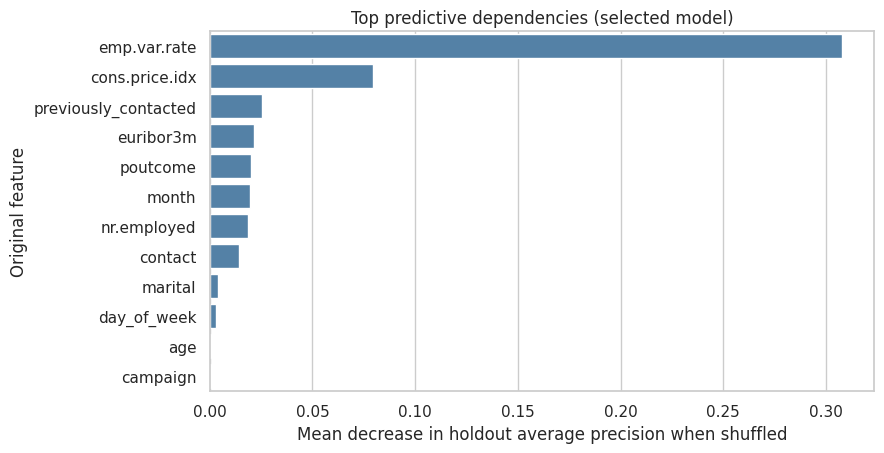

In [14]:
# Built-in sklearn permutation operates on original columns before the pipeline; separate from causal explanation.
imp=permutation_importance(winner,X_test,y_test,scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=2)
importance=pd.DataFrame({'feature':X_test.columns,'AP_decrease_mean':imp.importances_mean,'AP_decrease_sd':imp.importances_std}).sort_values('AP_decrease_mean',ascending=False)
importance.to_csv(RESULT/'permutation_importance.csv',index=False)
display(importance.head(12).round(4))
fig,ax=plt.subplots(figsize=(9,4.7))
sns.barplot(data=importance.head(12),x='AP_decrease_mean',y='feature',color='steelblue',ax=ax)
ax.set(title='Top predictive dependencies (selected model)',xlabel='Mean decrease in holdout average precision when shuffled',ylabel='Original feature')
fig.tight_layout();fig.savefig(FIG/'05_permutation_importance.png',dpi=160,bbox_inches='tight');plt.show()

## 8. Business findings and recommendations

**Plain-language interpretation:** The bank should not use a fixed "always call" strategy or rely on accuracy alone. A model can prioritize likely subscribers, but subscription base rates are low and a ranking score is **not** a calibrated revenue estimate. Which segments will yield positive incremental profit requires a prospective experiment. Because the original data are from 2008–2010 Portugal, out-of-time and present-day validation are essential.

**Recommended actions:** (1) use the trained ranking **only as a historical proof of concept**; (2) benchmark ranked calling against a random outreach holdout under equal capacity and consent constraints; (3) collect contact cost, eventual sales, and customer experience; (4) monitor conversion and performance by group and contact month; (5) refit on recent cohorts with a time-separated test before production; (6) always exclude post-call `duration` from pre-call decisions. Model importance indicates associations, not demographic targeting policy.

**Limitations:** The sample is 12,000/41,188 records, randomly sampled and stratified. Dataset rows are contact records with no stable customer ID; repeated customers may appear across splits. Models use historical month/economic conditions, which may not generalize to future periods. Three-fold CV estimates have variability; small grids do not guarantee global optimum. No temporal validation, probability calibration, incremental causal impact, revenue optimization, or fairness audit has been completed.

In [15]:
summary={
 'full_rows':len(df),'full_positive':int((df.y=='yes').sum()),'full_positive_rate':positive_rate,
 'campaigns_in_source_paper':17,'model_sample':MODEL_N,'train_rows':len(X_train),'test_rows':len(X_test),
 'cv_winner':winner_name,'cv_winner_AP':float(search_table.iloc[0].cv_AP),
 'test_winner_AP':float(tuned_table.loc[winner_name,'average_precision']),
 'test_winner_ROC_AUC':float(tuned_table.loc[winner_name,'roc_auc']),
 'test_winner_accuracy':float(tuned_table.loc[winner_name,'accuracy']),
 'test_winner_recall':float(tuned_table.loc[winner_name,'recall']),
 'test_winner_precision':float(tuned_table.loc[winner_name,'precision']),
 'top_20pct_precision':subset_precision,'top_20pct_lift':lift,
 'dataset_sha256':source_hash,'modeling_seed':SEED,
}
pd.Series(summary,dtype=object).to_csv(RESULT/'audit_summary.csv',header=['value'])
print('Final empirical summary:')
for k,v in summary.items():print(f'{k}: {v}')
print('Review source paper and plots before submitting a repository link.')

Final empirical summary:
full_rows: 41188
full_positive: 4640
full_positive_rate: 0.11265417111780131
campaigns_in_source_paper: 17
model_sample: 12000
train_rows: 9600
test_rows: 2400
cv_winner: Logistic regression
cv_winner_AP: 0.44812404806875333
test_winner_AP: 0.46244836252022276
test_winner_ROC_AUC: 0.7751278038601982
test_winner_accuracy: 0.9029166666666667
test_winner_recall: 0.25925925925925924
test_winner_precision: 0.6796116504854369
top_20pct_precision: 0.3541666666666667
top_20pct_lift: 3.1481481481481484
dataset_sha256: 233e260d5d1d506a2c10381da5b8c2f75f2c08d1b373ca7b825e39ebe1bd30df
modeling_seed: 42
Review source paper and plots before submitting a repository link.
